# Cached XLM-R user aggregation: T0 mean versus T1 maximum
The same prepared tweets and cached 768-dimensional tweet vectors feed both arms. Preserve all Phase-2 splits, transformations and masks. No LM inference, token-pooling changes, graph inputs, descriptions, pseudo-labels or test evaluation. Historical cache provenance limitations remain explicit.
Fixed temporal-plus-text architecture: 33→48 profile/behavioral; 14→16 temporal statistics/masks; 768→16 frozen-vector projection; concatenation80→32→1. Both arms have 16,897 trainable parameters. The temporal-only reference is contextual, not a matched-capacity control.

In [1]:
from pathlib import Path
import sys
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'configs/text_aggregation_v1.json').exists())
sys.path.insert(0, str(ROOT))
from src.text_aggregation import run, verify
output_dir = run(ROOT)
print('OUTPUT_VERSION:', output_dir)
print(verify(ROOT, output_dir))

Training T0_mean, seed 42


T0_mean, seed 42, epoch 25: validation BCE 0.6344


T0_mean, seed 42, epoch 50: validation BCE 0.6907


Training T1_max, seed 42


T1_max, seed 42, epoch 25: validation BCE 0.6444


...

Training T1_max, seed 44


T1_max, seed 44, epoch 25: validation BCE 0.5538


T1_max, seed 44, epoch 50: validation BCE 0.5516


OUTPUT_VERSION: C:\Users\p.vazifeh\Desktop\University\Project\Bot Detection Implementation\results\versions\text_aggregation_v1\20260923T050904839674Z_311fdde2


{'training_runs': 6, 'checkpoints_reloaded': 12, 'keyed_representation_matrices': 4, 'single_tweet_users_verified': {'train': 152, 'validation': 28}, 'test_inputs_parsed': 0}


## Fixed protocol
Seeds42/43/44; all671 training users; 50 epochs; batch32; AdamW lr0.001 decay0.0001; dropout0.3; training-only positive weight540/131. Paired initial state and actual batch-order hashes must match. Select earliest minimum unweighted validation BCE, retain final checkpoints, threshold0.5. All144 validation users remain included.
Single-tweet representations must match exactly. Missing vectors remain unavailable in saved representations and are masked before projection in the model. No description substitution. All current train/validation users have tweets, so software missingness tests do not establish empirical missing-text robustness.
Primary comparison: paired selected-checkpoint T1−T0 F1. Consistent improvement requires positive F1 changes in all three seeds and no lower mean AP. No automatic promotion. Reused validation and three seeds do not provide an unbiased final estimate.

,arm,policy,cohort,bot_f1_mean,bot_f1_std,bot_precision_mean,bot_precision_std,bot_recall_mean,bot_recall_std,roc_auc_mean,roc_auc_std,average_precision_mean,average_precision_std,brier_mean,brier_std
0,T0_mean,best_unweighted_validation_loss,11_to_50,0.462188,0.010135,0.356488,0.030694,0.666667,0.066667,0.684058,0.011863,0.540193,0.020232,0.242185,0.014741
1,T0_mean,best_unweighted_validation_loss,2_to_10,0.552821,0.012435,0.525641,0.022206,0.583333,0.000000,0.797804,0.014674,0.639323,0.043418,0.148274,0.012762
2,T0_mean,best_unweighted_validation_loss,all,0.472511,0.025369,0.379500,0.040804,0.630952,0.020620,0.756979,0.006387,0.536256,0.015075,0.182271,0.015384
3,T0_mean,best_unweighted_validation_loss,missing_text,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,T0_mean,best_unweighted_validation_loss,one_tweet,0.216667,0.202073,0.130952,0.125424,0.666667,0.577350,0.864198,0.113150,0.291667,0.190941,0.118521,0.025008
5,T0_mean,last,11_to_50,0.447347,0.079781,0.358586,0.079734,0.600000,0.066667,0.667150,0.029322,0.543636,0.026222,0.250730,0.032127
6,T0_mean,last,2_to_10,0.558263,0.066607,0.543821,0.117397,0.583333,0.000000,0.768088,0.020540,0.594078,0.048833,0.156081,0.030240
7,T0_mean,last,all,0.468010,0.076272,0.384755,0.089393,0.607143,0.035714,0.733580,0.025055,0.520471,0.024985,0.189627,0.033391
8,T0_mean,last,missing_text,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,T0_mean,last,one_tweet,0.307407,0.167160,0.189815,0.124485,1.000000,0.000000,0.839506,0.140220,0.422619,0.500106,0.122402,0.050589


,seed,policy,cohort,delta_bot_f1,delta_bot_precision,delta_bot_recall,delta_roc_auc,delta_average_precision,delta_brier
0,42,best_unweighted_validation_loss,all,0.000000,0.000000,0.000000,0.002771,-0.000280,-0.000378
1,42,best_unweighted_validation_loss,one_tweet,0.000000,0.000000,0.000000,0.000000,0.000000,-0.001703
2,42,best_unweighted_validation_loss,2_to_10,-0.019943,-0.033333,0.000000,0.013566,0.007201,-0.000593
3,42,best_unweighted_validation_loss,11_to_50,0.009752,0.010417,0.000000,-0.001449,-0.000821,0.000425
4,42,best_unweighted_validation_loss,missing_text,NaN,NaN,NaN,NaN,NaN,NaN
5,42,last,all,0.014109,0.016173,0.000000,-0.002463,-0.018408,0.003175
6,42,last,one_tweet,0.050000,0.031746,0.000000,0.000000,0.000000,-0.016346
7,42,last,2_to_10,-0.016092,-0.022876,0.000000,-0.003876,-0.017323,0.015290
8,42,last,11_to_50,0.016537,0.019048,0.000000,-0.001449,-0.011343,0.001211
9,42,last,missing_text,NaN,NaN,NaN,NaN,NaN,NaN


,seed,arm,policy,epoch,n,bots,threshold,bot_precision,bot_recall,bot_f1,...,fp,fn,tp,predicted_bots,roc_auc,average_precision,pos_weight,parameter_count,validation_weighted_loss,validation_unweighted_loss
0,42,temporal_branch,best_unweighted_validation_loss,12,144,28,0.5,0.367347,0.642857,0.467532,...,31,10,18,49,0.773399,0.534680,4.122137,4081,0.934310,0.557748
1,42,temporal_branch,last,50,144,28,0.5,0.333333,0.678571,0.447059,...,38,9,19,57,0.714901,0.475800,4.122137,4081,1.319343,0.721112
2,43,temporal_branch,best_unweighted_validation_loss,21,144,28,0.5,0.365385,0.678571,0.475000,...,33,9,19,52,0.758621,0.557178,4.122137,4081,1.000583,0.538830
3,43,temporal_branch,last,50,144,28,0.5,0.320755,0.607143,0.419753,...,36,11,17,53,0.732451,0.527168,4.122137,4081,1.245663,0.616335
4,44,temporal_branch,best_unweighted_validation_loss,16,144,28,0.5,0.400000,0.642857,0.493151,...,27,10,18,45,0.771552,0.566855,4.122137,4081,0.937399,0.532124
5,44,temporal_branch,last,50,144,28,0.5,0.352941,0.642857,0.455696,...,33,10,18,51,0.740764,0.552051,4.122137,4081,1.191297,0.606488


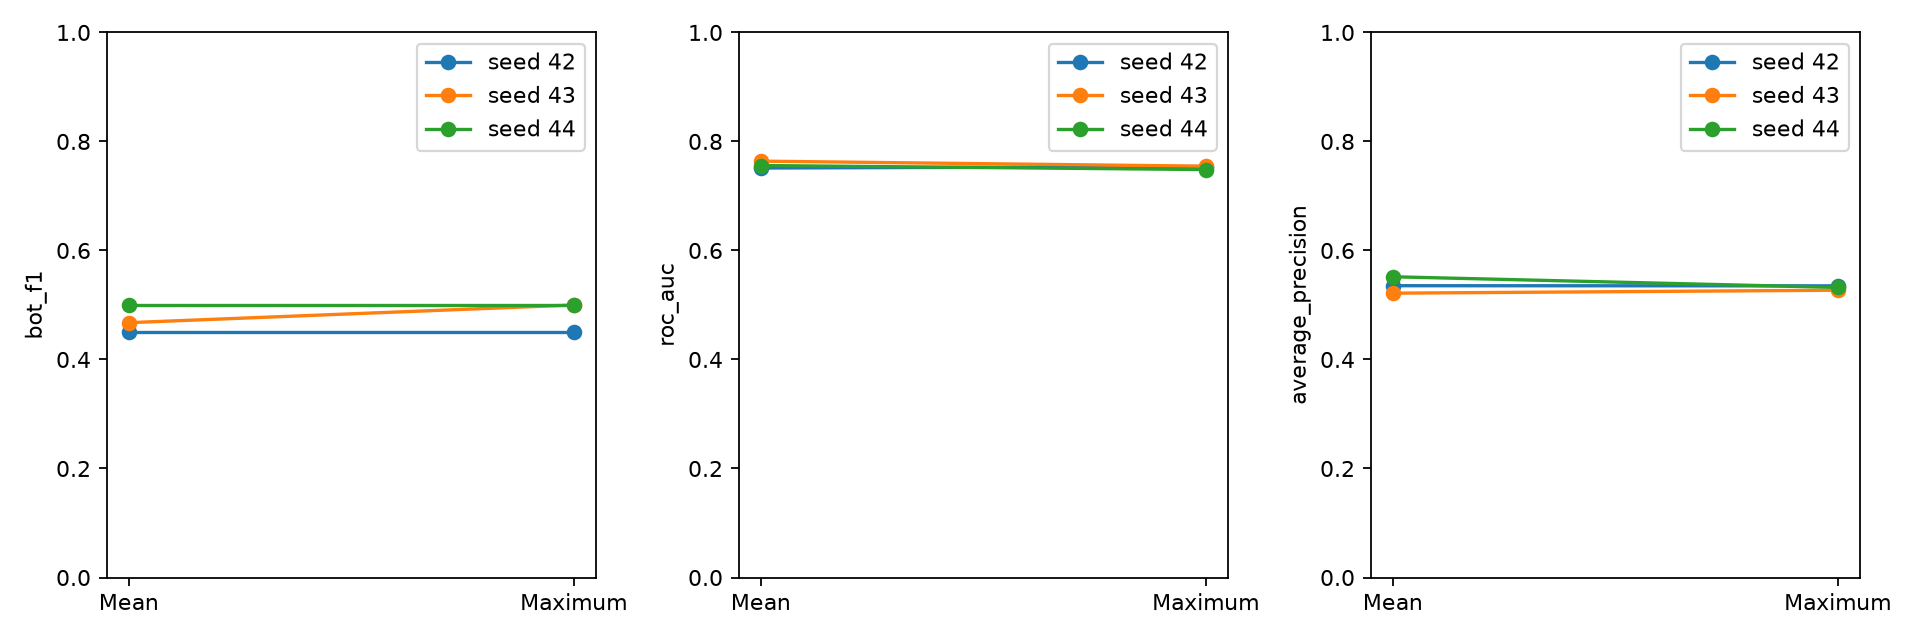

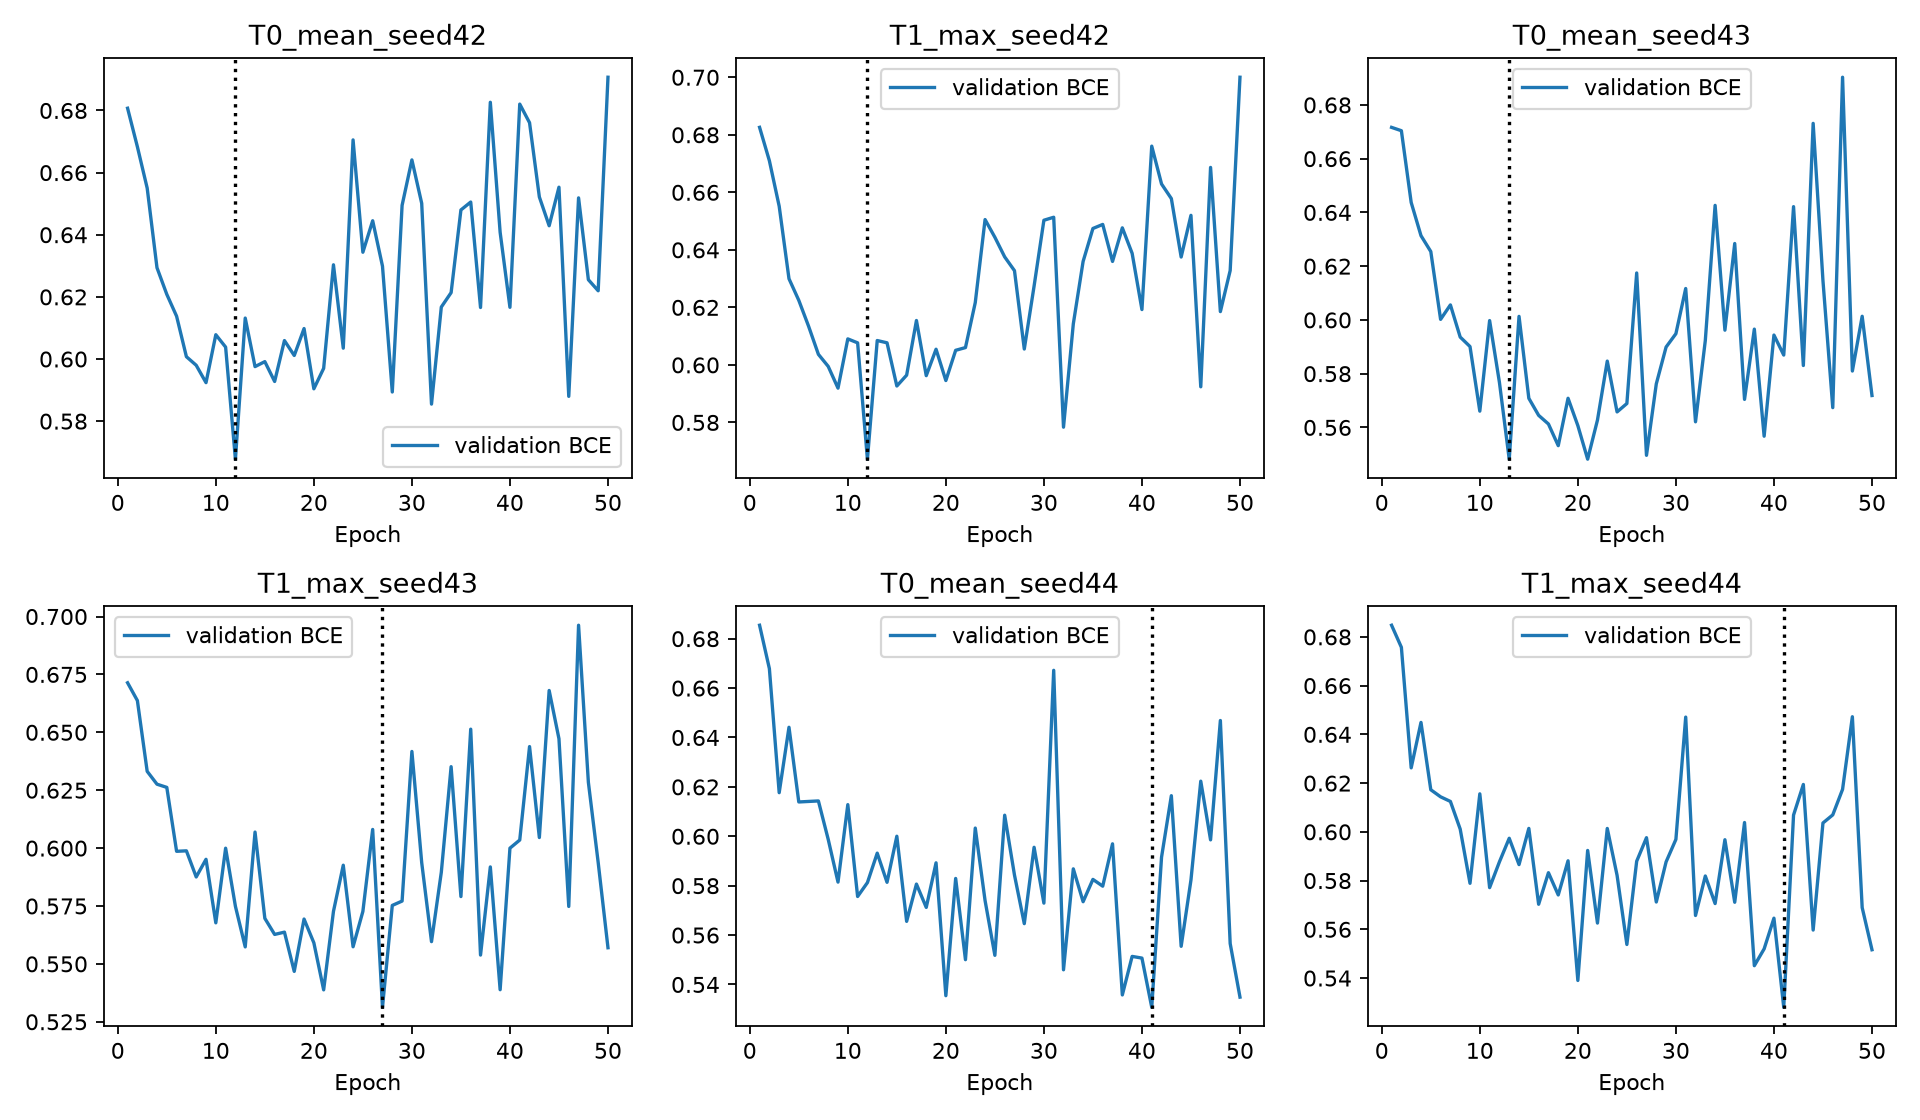

In [2]:
import pandas as pd
from IPython.display import display, Image
summary = pd.read_csv(output_dir / 'seed_summary.csv')
display(summary)
display(pd.read_csv(output_dir / 'paired_effects.csv'))
display(pd.read_csv(output_dir / 'temporal_reference_validation.csv'))
display(Image(filename=str(output_dir / 'figures/paired_metrics.png')))
display(Image(filename=str(output_dir / 'figures/learning_curves.png')))

In [3]:
norms = pd.read_csv(output_dir / 'embedding_norms.csv')
display(norms.groupby(['split','aggregation']).l2_norm.describe())
display(norms.groupby(['split','aggregation']).tweet_count.describe())
print('No test evaluation or threshold tuning. See reports/TEXT_AGGREGATION_EXPERIMENT.md.')

count       mean       std        min        25%  \
split      aggregation                                                     
train      T0_mean      671.0  18.907315  0.076823  18.464261  18.866188   
           T1_max       671.0  18.874821  0.102593  18.332691  18.826237   
validation T0_mean      144.0  18.904999  0.062583  18.705213  18.878375   
           T1_max       144.0  18.882409  0.084978  18.529906  18.839403   

                              50%        75%        max  
split      aggregation                                   
train      T0_mean      18.910120  18.955055  19.086084  
           T1_max       18.880261  18.940578  19.086084  
validation T0_mean      18.906076  18.940535  19.035177  
           T1_max       18.883915  18.932877  19.119180

count       mean        std  min  25%  50%    75%  \
split      aggregation                                                      
train      T0_mean      671.0  19.338301  20.202416  1.0  2.0  9.0  47.50   
           T1_max       671.0  19.338301  20.202416  1.0  2.0  9.0  47.50   
validation T0_mean      144.0  18.180556  19.804518  1.0  2.0  7.0  37.25   
           T1_max       144.0  18.180556  19.804518  1.0  2.0  7.0  37.25   

                         max  
split      aggregation        
train      T0_mean      50.0  
           T1_max       50.0  
validation T0_mean      50.0  
           T1_max       50.0

No test evaluation or threshold tuning. See reports/TEXT_AGGREGATION_EXPERIMENT.md.
